# GP2 Bioinformatics Training Workshop Argentina  

## Whole-Genome Data Analysis - Expansion Hunter

<span style="background-color: #90EE90">GP2 ❤️ Open Science 😍</span>

**Module:** STR analysis with ExpansionHunter

**Author:** Carlos Hernández and Zih-Hua Fang on behalf of the Global Parkinson's Genetics Program (ASAP)

**Estimated Computation and Runtime:**

**Estimated Specifications:** Default; 4 CPU,  15 GB Memory, 50 GB Persistent Disk Size  
**Estimated Runtime:** 30 min.  
**Date Last Updated:** 20/04/2026

## Notebook Summary

##### 2. [Getting Started](##2)
This section goes through:

- Set up environment
- Install Expansion Hunter (https://github.com/Illumina/ExpansionHunter)
- Prepare inputs that are required for Expansion Hunter to workspace

##### 3. [Run EH using a predefined catalogue](##2)
This section goes through:

- Run ExpansionHunter using variant catalogue
- Read the output to interpret the results

# Getting Started 

## Set up environment

In [ ]:
# Use the os package to interact with the environment
import os

# Bring in Pandas for Dataframe functionality
import pandas as pd

# Numpy for basics
import numpy as np

# Use StringIO for working with file contents
from io import StringIO

# Enable IPython to display matplotlib graphs
import matplotlib.pyplot as plt
%matplotlib inline

#Import Sys
import sys as sys

from pathlib import Path

## Install Expansion Hunter

In [ ]:
# Point mamba/conda to a package cache the current user owns
os.environ["CONDA_PKGS_DIRS"] = os.path.expanduser("~/.conda/pkgs")

In [ ]:
mamba create -n expansionhunter -c bioconda -c conda-forge expansionhunter -y

## Prepare inputs that are required for Expansion Hunter to workspace

In [ ]:
# Ws-files path
ws_files = '/home/jupyter/workspace/ws_files'

# define google bucket paths for the files
ref_genome       = "gs://gcp-public-data--broad-references/hg38/v0/Homo_sapiens_assembly38.fasta"
ref_genome_index = "gs://gcp-public-data--broad-references/hg38/v0/Homo_sapiens_assembly38.fasta.fai"
cram1            = "ftp://ftp.sra.ebi.ac.uk/vol1/run/ERR323/ERR3239351/NA18522.final.cram" # Positive Sample
cram1_index      = "ftp://ftp.sra.ebi.ac.uk/vol1/run/ERR323/ERR3239351/NA18522.final.cram.crai"
cram2            = "ftp://ftp.sra.ebi.ac.uk/vol1/run/ERR324/ERR3242196/HG01889.final.cram" # Negative Sample
cram2_index      = "ftp://ftp.sra.ebi.ac.uk/vol1/run/ERR324/ERR3242196/HG01889.final.cram.crai"

if not os.path.exists(f"{ws_files}/Reference/Homo_sapiens_assembly38.fasta"):
    !gsutil -m cp {ref_genome} {ws_files}/Reference

if not os.path.exists(f"{ws_files}/Reference/Homo_sapiens_assembly38.fasta.fai"):
    !gsutil -m cp {ref_genome_index} {ws_files}/Reference

if not os.path.exists(f"{ws_files}/CRAMs/{os.path.basename(cram1)}"):
    !wget {cram1} -O {ws_files}/CRAMs/{os.path.basename(cram1)}

if not os.path.exists(f"{ws_files}/CRAMs/{os.path.basename(cram1_index)}"):
    !wget {cram1_index} -O {ws_files}/CRAMs/{os.path.basename(cram1_index)}

if not os.path.exists(f"{ws_files}/CRAMs/{os.path.basename(cram2)}"):
    !wget {cram2} -O {ws_files}/CRAMs/{os.path.basename(cram2)}

if not os.path.exists(f"{ws_files}/CRAMs/{os.path.basename(cram2_index)}"):
    !wget {cram2_index} -O {ws_files}/CRAMs/{os.path.basename(cram2_index)}

## Add your name and create a directory for your analysis

In [ ]:
traineeID = "Cesar_Avila"
WORK_DIR = f"/home/jupyter/workspace/ws_files/INTERMEDIATE_LEVEL_WORKSHOP/ExpansionHunter_{traineeID}"
! mkdir -p {WORK_DIR}

In [ ]:
os.chdir(WORK_DIR)

# Overview of Short tandem repeats

## Short Tandem Repeats (STRs)

**Definition:** Short DNA motifs (2–6 bp) repeated consecutively at a specific 
genomic locus. Repeat number varies between individuals due to a high mutation 
rate from DNA polymerase slippage during replication.

**Relevance:**
- Highly polymorphic → useful as genetic markers (ancestry, forensics, linkage)
- Pathogenic expansions cause several neurological diseases 
  (e.g., Huntington's disease, spinocerebellar ataxias, C9orf72 ALS/FTD)

**Reference:** [STRipy Database of Short Tandem Repeats](https://stripy.org/database) — 
catalogue of disease-associated STR loci with normal/intermediate/pathogenic 
repeat thresholds and inheritance patterns.

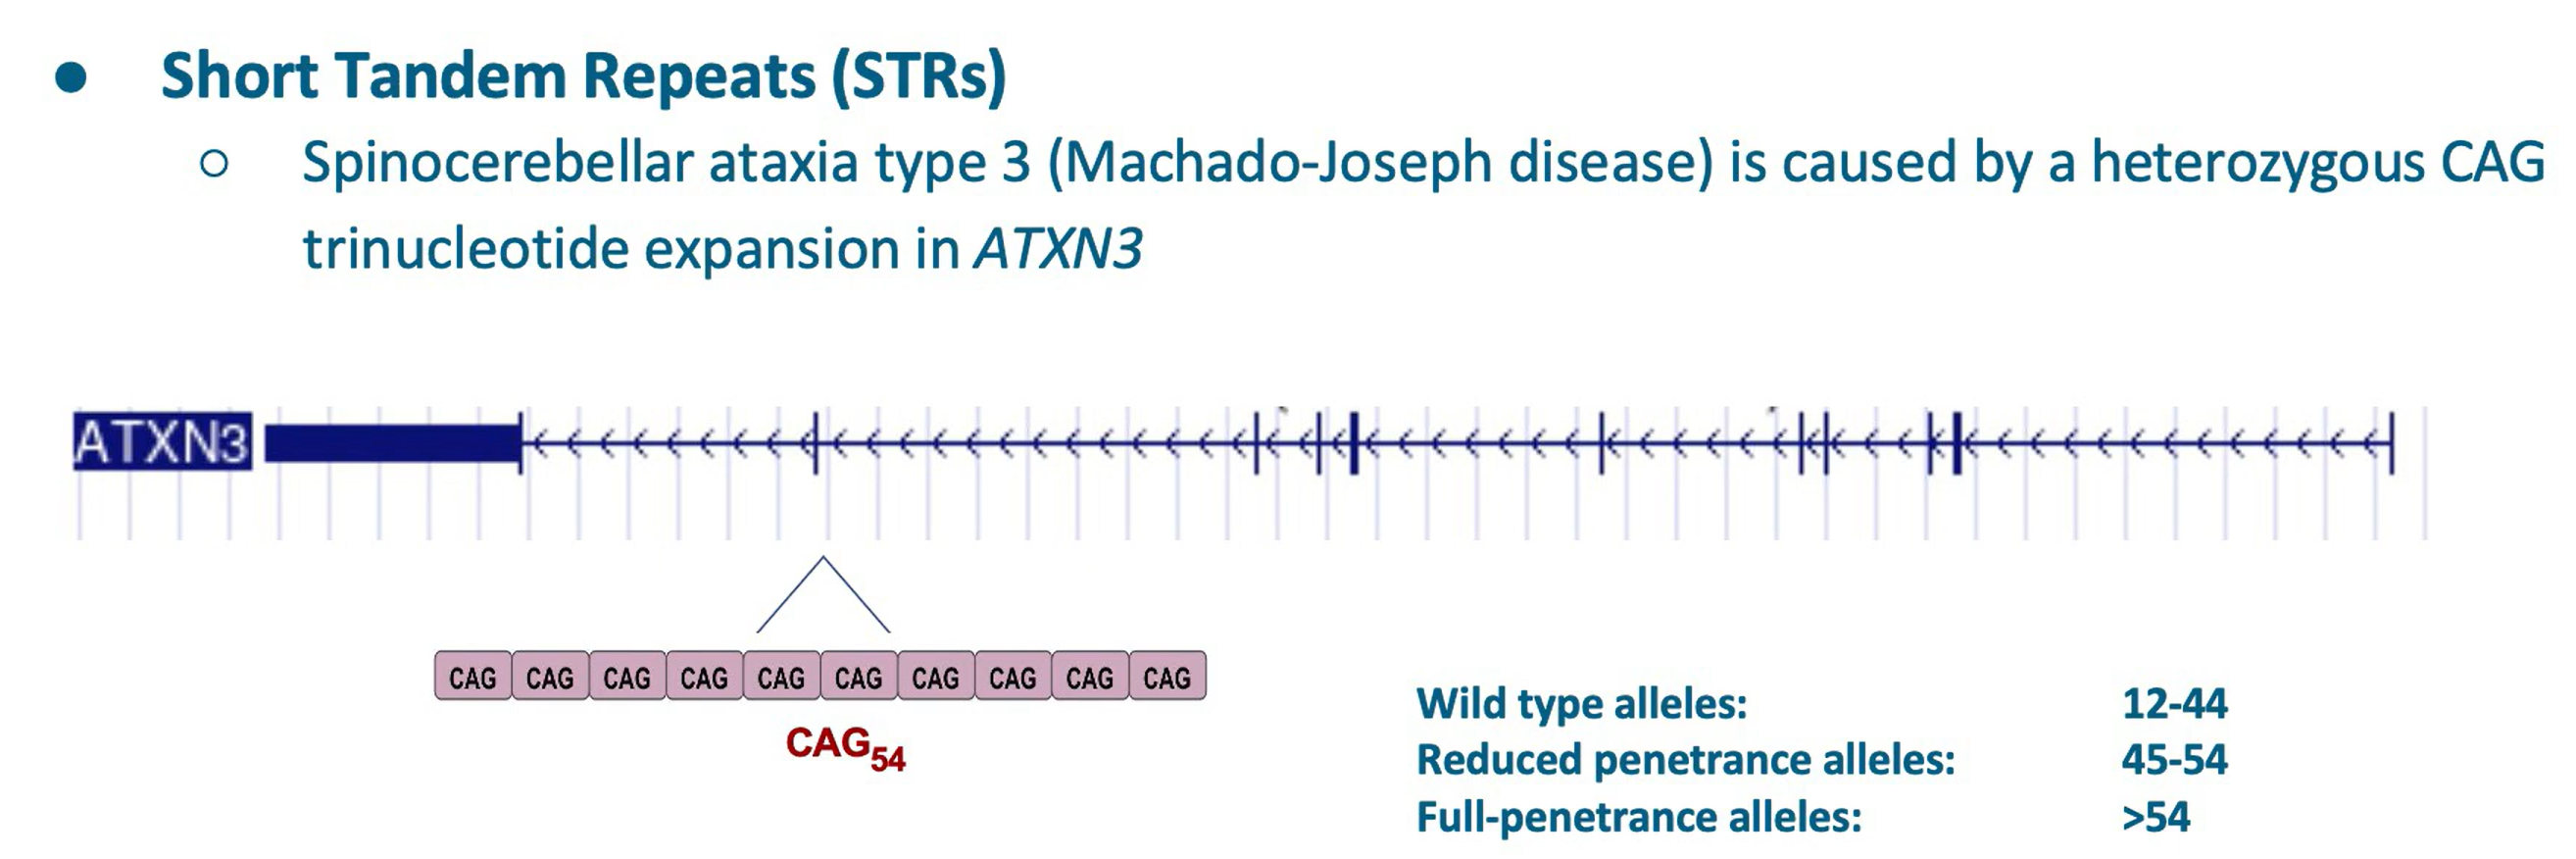

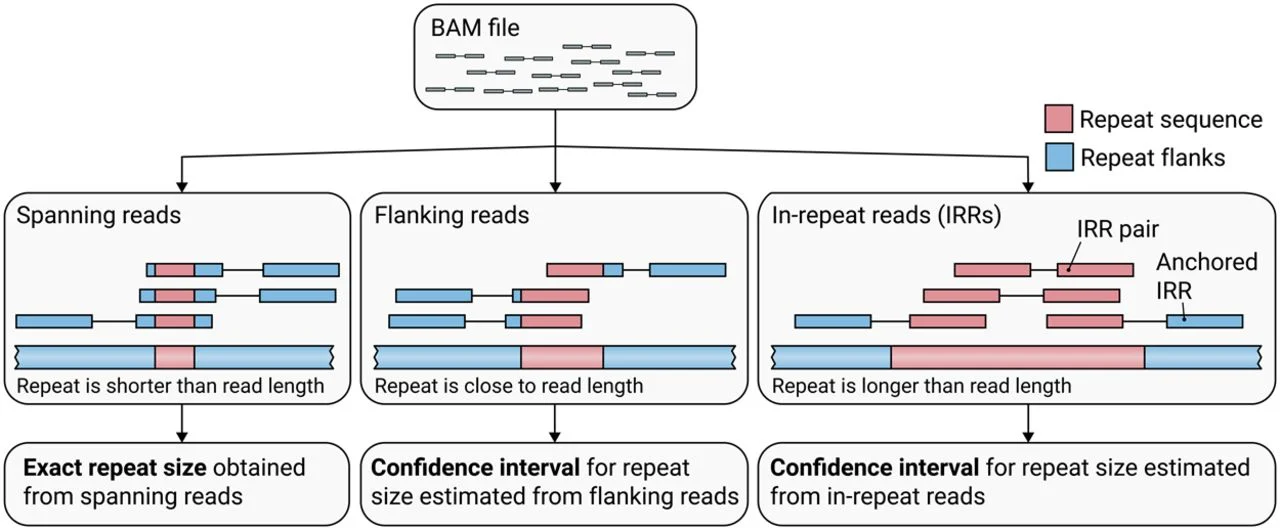

## Variant Catalog for ExpansionHunter

ExpansionHunter requires a **variant catalog** (JSON file) that defines, for each 
STR locus: reference coordinates, repeat motif structure (regex), and variant type. 
Without this catalog, ExpansionHunter doesn't know which regions to genotype.

**Options to obtain/generate a catalog:**

1. **Predefined catalogs ([Illumina/ExpansionHunter GitHub](https://github.com/Illumina/ExpansionHunter)):**
   - Default catalogs live in the [`variant_catalog/`](https://github.com/Illumina/ExpansionHunter/tree/master/variant_catalog) 
     folder (hg19/hg38 versions), ~60 known pathogenic loci (e.g., HTT, ATXN2, 
     ATXN3, C9orf72)
   - Genome-wide catalog ([Illumina/RepeatCatalogs](https://github.com/Illumina/RepeatCatalogs)): 
     ~174,293 polymorphic STRs + 30+ known pathogenic loci
   - Both in JSON format, ready to use with `--variant-catalog`

2. **Web-based generator (STRipy Catalogue Creator):**
   - [stripy.org/expansionhunter-catalog-creator](https://stripy.org/expansionhunter-catalog-creator)
   - Two ways to build a catalog:
     - Convert a BED file with your own loci of interest
     - Manually select known pathogenic loci from a list
   - Can also be generated via command line (API available)

In [ ]:
# Download the GRCh38 default variant catalog from Illumina/ExpansionHunter into WORKDIR
#! wget -O {WORK_DIR}/variant_catalog.json \
#    https://raw.githubusercontent.com/Illumina/ExpansionHunter/master/variant_catalog/grch38/variant_catalog.json

## STR genotyping workflow

1. **Input:** BAM/CRAM (aligned, ≥10x coverage recommended)
2. **Variant catalog:** JSON defining locus coordinates + repeat structure 
   (default Illumina catalog, RepeatCatalogs genome-wide, or STRipy-generated)
3. **ExpansionHunter:** genotypes repeat length at each locus → outputs VCF/JSON 
   + realigned BAM
4. **REViewer:** takes the realigned BAM + VCF + catalog → produces an SVG 
   read-pileup image for visual confirmation of the call at a specific locus
5. **Downstream:** aggregate REPCN across cohort/ancestry groups → compare to 
   pathogenic thresholds (e.g., STRipy database) → flag expansion carriers

**Flow:** `BAM/CRAM + catalog → ExpansionHunter → VCF/JSON + realigned BAM → REViewer → visual QC`

# Run Expansion Hunter

In [ ]:
%%bash -s {WORK_DIR}
set -euo pipefail
WORK_DIR=$1
ws_files="/home/jupyter/workspace/ws_files"

REF=${ws_files}/Reference/Homo_sapiens_assembly38.fasta
OUTDIR=${WORK_DIR}

for SAMPLE in SAMPLE_01 SAMPLE_02 SAMPLE_03 SAMPLE_04 SAMPLE_06 SAMPLE_07 SAMPLE_08 SAMPLE_09 SAMPLE_10 SAMPLE_11 SAMPLE_12; do

    CRAM=${ws_files}/CRAMs/${SAMPLE}.cram

    mamba run -n expansionhunter ExpansionHunter  \
      --reads ${CRAM} \
      --reference ${REF} \
      --variant-catalog ${WORK_DIR}/variant_catalog.json \
      --output-prefix ${OUTDIR}/${SAMPLE} \
      --log-level debug

done

## Output formats — ExpansionHunter

ExpansionHunter produces two main outputs per sample:

- **`<prefix>.vcf`** — one record per locus in the catalog. Key fields:
  - `REPCN` — repeat count (genotype) for each allele, e.g. `22,45` (two alleles)
  - `REPCI` — confidence interval for each allele's repeat count
  - `SO` — support type (SPANNING / FLANKING / INREPEAT reads)
- **`<prefix>.json`** — same information in structured form, easier to parse 
  programmatically (used for batch analyses across cohorts)
- **`<prefix>_realigned.bam`** — reads realigned to the repeat locus, required 
  as input for REViewer visualization

**Reading tip:** always check `REPCI` before trusting `REPCN` — 
a wide confidence interval (e.g., `REPCN=45` but `REPCI=30-60`) means low 
confidence, usually from low coverage or a very long/impure repeat.

## Read the result

In [ ]:
import json
import pandas as pd
import re
import os

files = [
f"{WORK_DIR}/SAMPLE_01.json",
f"{WORK_DIR}/SAMPLE_02.json",
f"{WORK_DIR}/SAMPLE_03.json",
f"{WORK_DIR}/SAMPLE_04.json",
f"{WORK_DIR}/SAMPLE_06.json",
f"{WORK_DIR}/SAMPLE_07.json",
f"{WORK_DIR}/SAMPLE_08.json",
f"{WORK_DIR}/SAMPLE_09.json",
f"{WORK_DIR}/SAMPLE_10.json",
f"{WORK_DIR}/SAMPLE_11.json",
f"{WORK_DIR}/SAMPLE_12.json"
]

def parse_counts(s):
    if not s or s == "()":
        return 0
    pairs = re.findall(r"\((\d+),\s*(\d+)\)", s)
    return sum(int(count) for _, count in pairs)

rows = []

for file in files:

    sample = os.path.basename(file).replace(".json","")

    with open(file) as f:
        data = json.load(f)

    for locus_id, locus in data["LocusResults"].items():

        for var_id, var in locus.get("Variants", {}).items():

            genotype = var.get("Genotype", None)

            allele1, allele2 = None, None
            if genotype:
                parts = genotype.split("/")
                if len(parts) == 2:
                    allele1, allele2 = parts

            spanning = parse_counts(var.get("CountsOfSpanningReads", ""))
            flanking = parse_counts(var.get("CountsOfFlankingReads", ""))
            inrepeat = parse_counts(var.get("CountsOfInrepeatReads", ""))

            rows.append({
                "sample": sample,
                "locus": locus_id,
                "allele1": allele1,
                "allele2": allele2,
                "genotype": genotype,
                "spanning": spanning,
                "flanking": flanking,
                "inrepeat": inrepeat
            })

df = pd.DataFrame(rows)
df

## View the result

In [ ]:
mamba create -n reviewer -c bioconda -c conda-forge reviewer -y

In [ ]:
%%bash -s {WORK_DIR}

ws_files="/home/jupyter/workspace/ws_files"
WORK_DIR=$1

for SAMPLE in  SAMPLE_07 SAMPLE_09; do

    VCF=${WORK_DIR}/${SAMPLE}.vcf
    BAM=${WORK_DIR}/${SAMPLE}_realigned.bam

    samtools sort -o ${BAM%.bam}.sorted.bam ${BAM}
    samtools index ${BAM%.bam}.sorted.bam

    mamba run -n reviewer REViewer \
      --reads ${BAM%.bam}.sorted.bam \
      --vcf ${VCF} \
      --reference ${ws_files}/Reference/Homo_sapiens_assembly38.fasta \
      --catalog ${WORK_DIR}/variant_catalog.json \
      --locus FGF14 \
      --output-prefix ${WORK_DIR}/TCF4_${SAMPLE} ;
done

## QC and common pitfalls — STR analysis

- **Minimum coverage:** ExpansionHunter needs ≥10x at the locus; lower coverage 
  inflates `REPCI` width and reduces genotype confidence
- **Ancestry-specific reference ranges:** "normal" repeat count can shift 
  between ancestry groups.
- **Low-complexity/repetitive regions:** misalignment near the repeat can 
  inflate or truncate apparent repeat length — always sanity-check with REViewer 
  before reporting a carrier
- **CRAM version compatibility:** newer CRAM (e.g., 3.1 from DRAGEN 4.4.7) may 
  not be readable by older htslib bundled in some tools — transcode to BAM if 
  genotyping/visualization fails unexpectedly
- **Off-catalog loci:** ExpansionHunter only genotypes loci defined in the 
  catalog — a "negative" result for a gene not in your catalog is meaningless, 
  not a true negative

## Complex motifs

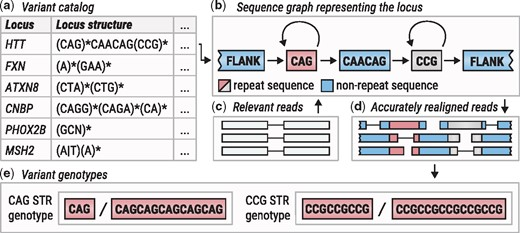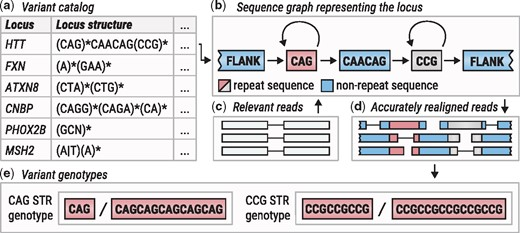